# Preparing dataframes for pseudobulking analysis - Sample_type_major2
## Using DC2 anndata object 20250629_DC2_bbknn_clustered2.h5ad 
* sum by sample, so for each DC2 subset (7 dataframes) made a dataframe that has genes as rows and integration_id (samples) as columns
* then make a metadata dataframe that has two columns --> integration_id and cancer type
* done on 29/09/26

### Using code from NR 2025-01-13_Pseudobulking.ipynb


In [1]:
#load packages
import scanpy as sc
import os
import pandas as pd

In [2]:
import tools
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns
import numpy as np
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [3]:
#change current directory 
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis'

In [3]:
# Read in the data 
data = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250629_DC2_bbknn_clustered2.h5ad')

### Use the NR raw data

* need to find raw DC2 dataset to do pseudobulking with LB 24.9.26
* can't find the raw DC2 dataset LB 29.9.26

In [6]:
# Read in the data 
#data = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NRclean_Raw_Data.h5ad')

In [7]:
data

AnnData object with n_obs × n_vars = 16643 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_CXCL9', 

## Add new (September 2026) cDC2 Annotations onto Data

In [4]:
# filter to just ovarian cancer
data2_oc = data[data.obs["cancer_with_H"].isin(["HGSOC"])]

In [9]:
data2_oc

View of AnnData object with n_obs × n_vars = 5372 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_C

In [5]:
# Assign DC2 annotations (from NR):
data2_oc.obs["cDC2_sub_annotated"] = data2_oc.obs["cDC2_Atlas_Subclusters"].map(
    {
        "1": "DC3-like cDC2",
        "3": "SIK3 cDC2",
        "4": "CD207-S100 cDC2",
        "5": "classical cDC2",
        "6": "ISG cDC2",
        "7": "classical cDC2",
        "8": "CD207-IL18 cDC2",
        "9": "CD207-LTB cDC2",
    }
)

/scratch/temp/31642676/ipykernel_3446192/1826711254.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data2_oc.obs["cDC2_sub_annotated"] = data2_oc.obs["cDC2_Atlas_Subclusters"].map(


In [6]:
# Set colours for cDC2_sub_annotated plot: - new
data2_oc.uns["cDC2_sub_annotated_colors"] = ['#7f7f7f','#bcbd22','#d62728','#1f77b4','#8c564b','#2ca02c','#c869c9']

/scratch/temp/31642676/ipykernel_3446192/369315642.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(data2_oc, color="cDC2_sub_annotated", size=20, save="29.9.26_DC2_annotated_v2.svg")


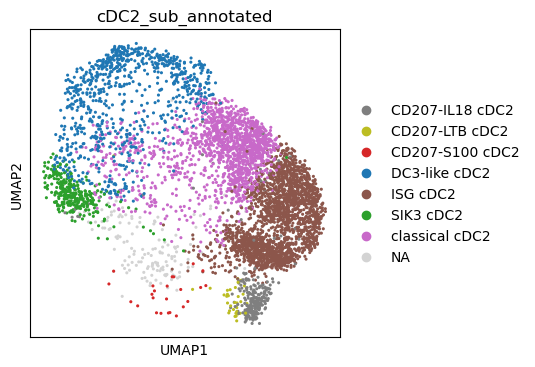

In [7]:
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data2_oc, color="cDC2_sub_annotated", size=20, save="29.9.26_DC2_annotated_v2.svg")

Remove cluster 2 and 10 from DC2 OC object

In [8]:
data2_oc = data2_oc[~data2_oc.obs["cDC2_Atlas_Subclusters"].isin(["2","10"])]

Add DC2 subcluster annotations

In [9]:
# Assign DC2 annotations (from NR):
data2_oc.obs["cDC2_sub_annotated"] = data2_oc.obs["cDC2_Atlas_Subclusters"].map(
    {
        "1": "DC3-like cDC2",
        "3": "SIK3 cDC2",
        "4": "CD207-S100 cDC2",
        "5": "classical cDC2",
        "6": "ISG cDC2",
        "7": "classical cDC2",
        "8": "CD207-IL18 cDC2",
        "9": "CD207-LTB cDC2",
    }
)

/scratch/temp/31642676/ipykernel_3446192/1826711254.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data2_oc.obs["cDC2_sub_annotated"] = data2_oc.obs["cDC2_Atlas_Subclusters"].map(


/scratch/temp/31642676/ipykernel_3446192/1132881505.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(data2_oc, color="cDC2_sub_annotated", size=20, save="_DC2_annotated_v2.svg")


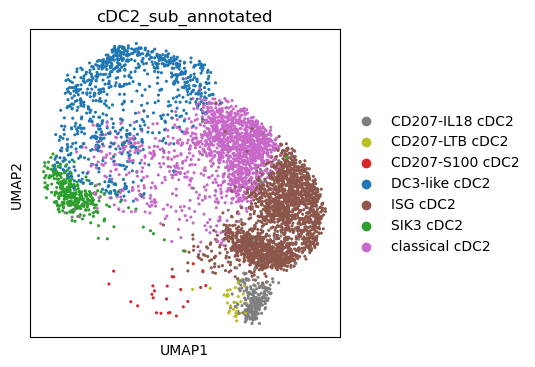

In [10]:
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data2_oc, color="cDC2_sub_annotated", size=20, save="_DC2_annotated_v2.svg")

# Make pseudobulk dataframes: 

In [13]:
#subset out each DC
data_CD207_IL18 = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "CD207-IL18 cDC2"]
data_CD207_LTB = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "CD207-LTB cDC2"]
data_CD207_S100 = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "CD207-S100 cDC2"]
data_ISG = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "ISG cDC2"]
data_SIK3 = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "SIK3 cDC2"]
data_dc2 = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "classical cDC2"]
data_dc3 = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "DC3-like cells"]

Redo DC3-like DC2s

In [11]:
data_dc3 = data2_oc[data2_oc.obs["cDC2_sub_annotated"] == "DC3-like cDC2"]

In [14]:
#checking how many samples in each (this will have to match metadata dataframe below)
num_unique_integration_ids = data_CD207_IL18.obs['integration_id'].nunique()
print(f"Number of unique integration_id values: {num_unique_integration_ids}")

Number of unique integration_id values: 68


In [15]:
data_CD207_IL18_matrix = data_CD207_IL18.X.toarray()
data_CD207_LTB_matrix = data_CD207_LTB.X.toarray()
data_CD207_S100_matrix = data_CD207_S100.X.toarray()
data_ISG_matrix = data_ISG.X.toarray()
data_SIK3_matrix = data_SIK3.X.toarray()
data_dc2_matrix = data_dc2.X.toarray()
data_dc3_matrix = data_dc3.X.toarray()

Don't need to analyse the data_CD207_LTB and data_CD207_S100 because there are too few samples in these

In [16]:
genes_IL18 = data_CD207_IL18.var_names
obs_IL18 = data_CD207_IL18.obs

genes_ISG = data_ISG.var_names
obs_ISG = data_ISG.obs

genes_SIK3 = data_SIK3.var_names
obs_SIK3 = data_SIK3.obs

genes_dc2 = data_dc2.var_names
obs_dc2 = data_dc2.obs

genes_dc3 = data_dc3.var_names
obs_dc3 = data_dc3.obs

In [17]:
# Create a DataFrame with cells as rows and genes as columns
data_IL18_df = pd.DataFrame(data_CD207_IL18_matrix, index= obs_IL18.index, columns=genes_IL18)
data_ISG_df = pd.DataFrame(data_ISG_matrix, index=obs_ISG.index, columns=genes_ISG)
data_SIK3_df = pd.DataFrame(data_SIK3_matrix, index=obs_SIK3.index, columns=genes_SIK3)
data_dc2_df = pd.DataFrame(data_dc2_matrix, index=obs_dc2.index, columns=genes_dc2)
data_dc3_df = pd.DataFrame(data_dc3_matrix, index=obs_dc3.index, columns=genes_dc3)

In [18]:
# Add integration_id
data_IL18_df['integration_id'] = obs_IL18['integration_id']
data_ISG_df['integration_id'] = obs_ISG['integration_id']
data_SIK3_df['integration_id'] = obs_SIK3['integration_id']
data_dc2_df['integration_id'] = obs_dc2['integration_id']
data_dc3_df['integration_id'] = obs_dc3['integration_id']

In [23]:
data_IL18_df.head()

,KLHL17,HES4,ISG15,AGRN,TNFRSF18,TNFRSF4,PRKCZ,MORN1,ACOT7,TNFRSF25,...,PCBP3,COL6A1,COL6A2,DIP2A,S100B,MT-ATP8,MT-ND4L,MT-ND5,MT-ND6,integration_id
GSE184880_Cancer1_GGGTCACCAAGCTGTT-1,-0.312636,-0.231267,-0.333832,-0.302964,-0.246503,-0.207477,-0.057514,-0.154915,-0.042970,-0.185047,...,-0.055274,-0.236097,-0.141486,-0.775398,1.512361,0.717415,0.206054,-1.220944,-2.759907,GSE184880_HGSOC_Cancer1
GSE184880_Cancer7_CCGTTCATCTGAACGT-1,-0.147420,-0.044970,0.766194,-0.191248,-0.125785,-0.085994,-0.133303,-0.060599,-0.730296,-0.164245,...,-0.018182,-0.128263,-0.006500,2.441629,-1.116272,0.814797,0.263725,1.298977,0.046047,GSE184880_HGSOC_Cancer7
GSE184880_Cancer7_GCAGCCAAGCATGCAG-1,-0.163051,0.082393,-0.676390,-0.188497,-0.080692,-0.016337,-0.119423,-0.044283,1.938908,-0.157368,...,0.029283,-0.149295,0.018535,-0.267492,-1.357644,0.380975,0.609065,0.982494,-1.354351,GSE184880_HGSOC_Cancer7
GSE184880_Norm3_TCTTAGTTCATCCTAT-1,-0.189837,-0.577371,0.585089,-0.306388,-0.262827,-0.289352,-0.147821,-0.155051,2.087192,-0.187412,...,-0.184021,-0.152827,-0.124566,-0.620991,0.844944,-0.823747,-0.677122,-0.515692,-0.528532,GSE184880_Healthy_Norm3
GSE213243_ascites_GCACGGTTCGGTCGAC-2,-0.185807,-0.307912,-0.525090,-0.249287,-0.248223,-0.231299,-0.090748,-0.124855,-0.088239,-0.149942,...,-0.049848,-0.169730,-0.137903,-0.562816,0.970236,0.713318,0.588214,-0.040694,-1.740526,GSE213243_HGSOC_ascites


In [19]:
# Group by integration_id and sum to pseudobulk
pseudobulk_IL18_df = data_IL18_df.groupby('integration_id').sum().transpose()
pseudobulk_ISG_df = data_ISG_df.groupby('integration_id').sum().transpose()
pseudobulk_SIK3_df = data_SIK3_df.groupby('integration_id').sum().transpose()
pseudobulk_dc2_df = data_dc2_df.groupby('integration_id').sum().transpose()
pseudobulk_dc3_df = data_dc3_df.groupby('integration_id').sum().transpose()

/scratch/temp/31642676/ipykernel_3446192/2541314046.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_IL18_df = data_IL18_df.groupby('integration_id').sum().transpose()
/scratch/temp/31642676/ipykernel_3446192/2541314046.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_ISG_df = data_ISG_df.groupby('integration_id').sum().transpose()
/scratch/temp/31642676/ipykernel_3446192/2541314046.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the f

In [25]:
pseudobulk_IL18_df.head()

integration_id,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-014_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-014_S1_CD45P_LEFT_OVARY,GSE180661_SPECTRUM-OV-014_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM-OV-022_S1_CD45P_ASCITES,GSE180661_SPECTRUM-OV-022_S1_CD45P_LEFT_ADNEXA,...,GSE180661_SPECTRUM-OV-115_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM-OV-115_S1_CD45P_RIGHT_ADNEXA,GSE180661_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,GSE180661_SPECTRUM-OV-118_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM-OV-118_S1_CD45P_RIGHT_ADNEXA,GSE184880_HGSOC_Cancer1,GSE184880_HGSOC_Cancer7,GSE184880_Healthy_Norm3,GSE213243_HGSOC_ascites,GSE217517_HGSOC_pt2
KLHL17,-0.112508,-0.283194,-0.143702,-0.276163,7.477765,11.635409,5.483738,-1.040186,-0.135567,-0.090924,...,-0.507995,-0.483163,9.676807,-0.214668,-0.490165,-0.312636,-0.310471,-0.189837,-0.331915,-0.155196
HES4,-0.264986,-1.700769,-0.977929,-1.499545,-0.816867,-9.154280,-4.247257,-1.126514,-0.468870,-0.259839,...,-2.137817,-1.683627,-1.439978,-0.546278,-1.966888,-0.231267,0.037423,-0.577371,-0.627276,-0.451250
ISG15,0.777906,4.378872,4.573073,7.404557,3.437072,7.736064,-1.695497,3.204520,2.613703,1.757031,...,-1.471739,-1.090166,0.913288,1.977566,0.295051,-0.333832,0.089804,0.585089,-1.149595,0.912919
AGRN,-0.179044,3.055382,-0.497781,-0.726722,-0.381368,0.703599,-2.514355,5.403947,-0.298194,-0.159759,...,-1.084713,1.565688,-0.899047,-0.371656,-1.135464,-0.302964,-0.379746,-0.306388,-0.468819,1.763780
TNFRSF18,-0.246008,-0.973920,-0.705225,-0.993596,-0.520289,-5.983735,-2.579263,-2.135563,-0.476812,-0.247935,...,-1.235309,-1.195558,-1.135822,-0.466419,-1.349246,-0.246503,-0.206476,-0.262827,-0.503950,-0.538941


In [26]:
pseudobulk_SIK3_df.head()

integration_id,GSE180661_SPECTRUM-OV-014_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-025_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-025_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-025_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM-OV-026_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-026_S1_CD45P_LEFT_ADNEXA,GSE180661_SPECTRUM-OV-031_S1_CD45P_LEFT_FALLOPIAN_TUBE,GSE180661_SPECTRUM-OV-036_S1_CD45P_RIGHT_ADNEXA,GSE180661_SPECTRUM-OV-037_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-037_S1_CD45P_LEFT_OVARY,...,GSE184880_HGSOC_Cancer1,GSE213243_HGSOC_ascites,GSE217517_HGSOC_pt1,GSE217517_HGSOC_pt2,GSE217517_HGSOC_pt3,GSE217517_HGSOC_pt4,GSE217517_HGSOC_pt5,GSE217517_HGSOC_pt7,PRJCA005422_HGSOC2_AS,PRJCA005422_HGSOC5_AS
KLHL17,-0.164133,-0.093817,-0.189470,-0.309300,-0.963992,-0.611749,-0.284617,-0.233463,-0.781061,-0.434765,...,-0.197295,-0.271263,-4.598551,5.688902,-4.013858,-0.043105,-0.327645,-0.472910,-0.656785,-0.106673
HES4,0.547674,-0.134628,-0.133401,-0.757546,-0.190768,0.477491,0.019735,-0.003495,-0.519163,-0.429333,...,-0.267847,0.073270,-7.711150,-26.802226,-4.932388,2.948609,5.592279,-0.288695,-0.652518,-0.273498
ISG15,-0.994187,0.704678,0.128517,-0.594421,4.625646,0.210457,-1.377299,-0.587937,0.029760,-1.169929,...,0.365875,-0.528978,-2.195218,18.746507,2.878119,2.267358,0.955563,0.341779,-1.043740,-0.323006
AGRN,-0.315614,-0.144305,-0.234818,-0.672629,2.522279,6.861380,-0.351723,-0.314469,3.800300,-0.689270,...,-0.333106,-0.242578,14.675630,23.360815,4.055729,-0.141400,-0.456483,4.920296,-1.148331,-0.198828
TNFRSF18,-0.026045,-0.223236,-0.137719,-0.143056,-0.192374,-0.260866,-0.253000,0.020265,-0.168886,-0.282832,...,-0.071056,-0.103982,-17.862181,-11.493110,-8.375777,-0.205488,-0.489221,-0.074843,-0.301204,-0.171432


In [27]:
pseudobulk_ISG_df.head()

integration_id,GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-008_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-014_S1_CD45P_ASCITES,GSE180661_SPECTRUM-OV-014_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-014_S1_CD45P_LEFT_OVARY,GSE180661_SPECTRUM-OV-014_S1_CD45P_PELVIC_PERITONEUM,...,GSE184880_Healthy_Norm4,GSE184880_Healthy_Norm5,GSE213243_HGSOC_ascites,PRJCA005422_HGSOC1_AS,PRJCA005422_HGSOC2_AS,PRJCA005422_HGSOC3_AS,PRJCA005422_HGSOC5_AS,PRJCA005422_HGSOC6_AS,PRJCA005422_HGSOC9_AS,PRJCA005422_HGSOC10_AS
KLHL17,-0.449840,-0.091206,-0.331570,-0.149130,-0.382372,-0.144369,-4.199458,-0.088441,-0.163509,-0.412636,...,-0.363586,-0.424697,31.805082,-0.497313,-20.921419,2.915612,4.358113,-4.080315,-0.911715,8.177622
HES4,-1.000063,-0.231956,-0.959150,-0.704135,-1.413325,-0.796144,-23.591700,-0.268820,-1.043802,-0.942834,...,-0.242639,-0.917645,-154.481998,-50.659757,-251.928998,-30.285243,-20.604367,-22.724336,-5.102049,-8.917504
ISG15,3.996419,0.870688,-1.558097,-0.725751,6.851283,1.933589,31.117852,-0.730720,3.600494,-1.367127,...,1.696716,-0.159143,-114.694826,32.436051,322.677833,83.213622,1.962341,20.578581,13.405084,12.599931
AGRN,-0.678797,-0.175956,-0.499524,-0.373436,4.344843,-0.389104,-4.891858,-0.190159,-0.442845,2.330117,...,-0.319246,-0.612321,-23.974767,-16.310542,68.100736,3.534685,2.729574,-7.480203,1.087864,1.918886
TNFRSF18,-0.746029,-0.213917,-0.550338,-0.480159,-1.126729,-0.482551,-10.189846,-0.211913,1.421723,1.171835,...,-0.277921,-0.768166,-65.098243,-28.867060,-131.308055,-15.835502,-13.505856,-11.021965,-3.586474,-6.782564


In [31]:
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis/DC2_Pseudobulk'

In [20]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis/DC2_Pseudobulk')

In [33]:
# save as csv
pseudobulk_IL18_df.to_csv("pseudobulk_IL18_data.csv", index=True)
pseudobulk_ISG_df.to_csv("pseudobulk_ISG_data.csv", index=True)
pseudobulk_SIK3_df.to_csv("pseudobulk_SIK3_data.csv", index=True)
pseudobulk_dc2_df.to_csv("pseudobulk_dc2_data.csv", index=True)
pseudobulk_dc3_df.to_csv("pseudobulk_dc3_data.csv", index=True)

In [21]:
pseudobulk_dc3_df.to_csv("pseudobulk_dc3_data.csv", index=True)

# Make metadata dataframes

In [35]:
data_CD207_IL18

View of AnnData object with n_obs × n_vars = 262 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_CX

In [37]:
metadata_IL18 = data_CD207_IL18.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()
metadata_ISG = data_ISG.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()
metadata_SIK3 = data_SIK3.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()
metadata_dc2 = data_dc2.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()
metadata_dc3 = data_dc3.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()


/scratch/temp/29084483/ipykernel_2271230/1116243768.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  metadata_IL18 = data_CD207_IL18.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()
/scratch/temp/29084483/ipykernel_2271230/1116243768.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  metadata_ISG = data_ISG.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()
/scratch/temp/29084483/ipykernel_2271230/1116243768.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=Fa

In [22]:
metadata_dc3 = data_dc3.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()

/scratch/temp/31642676/ipykernel_3446192/2430841273.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  metadata_dc3 = data_dc3.obs[['integration_id', 'sample_type_major2']].groupby('integration_id').first()


In [38]:
metadata_IL18.head()

,sample_type_major2
integration_id,
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_PELVIC_PERITONEUM,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_RIGHT_UPPER_QUADRANT,metastatic tumour


In [39]:
metadata_IL18.shape

(68, 1)

In [40]:
# set the index (integration_id) to be a column
metadata_IL18 = metadata_IL18.reset_index()
metadata_ISG = metadata_ISG.reset_index()
metadata_SIK3 = metadata_SIK3.reset_index()
metadata_dc2 = metadata_dc2.reset_index()
metadata_dc3 = metadata_dc3.reset_index()

In [41]:
metadata_IL18.head()

,integration_id,sample_type_major2
0,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPP...,metastatic tumour
1,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic tumour
2,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_...,metastatic tumour
3,GSE180661_SPECTRUM-OV-009_S1_CD45P_PELVIC_PERI...,metastatic tumour
4,GSE180661_SPECTRUM-OV-009_S1_CD45P_RIGHT_UPPER...,metastatic tumour


In [42]:
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis/DC2_Pseudobulk'

In [43]:
# save as csv
metadata_IL18.to_csv("pseudobulk_metadata_IL18.csv", index=False)
metadata_ISG.to_csv("pseudobulk_metadata_ISG.csv", index=False)
metadata_SIK3.to_csv("pseudobulk_metadata_SIK3.csv", index=False)
metadata_dc2.to_csv("pseudobulk_metadata_dc2.csv", index=False)
metadata_dc3.to_csv("pseudobulk_metadata_dc3.csv", index=False)